# Laboratorio — Clasificación con Regresión Logística
## Dataset Breast Cancer (Diagnóstico de Cáncer de Mama)

**Curso:** Sistemas Inteligentes  
**Tema:** Clasificación Binaria Supervisada mediante Regresión Logística  
**Estudiante:** Angel David Arenales Sandoval  
**Dataset:** Wisconsin Breast Cancer Diagnostic Dataset (`sklearn.datasets.load_breast_cancer`)

---

## 🎯 Pregunta central del laboratorio
> **¿Es posible determinar de forma confiable si un tumor mamario es benigno o maligno analizando características geométricas y morfológicas extraídas de imágenes microscópicas por punción con aguja fina (PAAF)?**

---

### 🗺️ Ruta de desarrollo del laboratorio:
**Comprensión del Problema → Exploración de Datos (EDA) → Limpieza y Calidad de Datos → Análisis de Correlación → Partición y Escalado → Entrenamiento del Modelo → Evaluación Exhaustiva (Métricas, Matriz, ROC/PR) → Análisis de Coeficientes → Conclusiones Clínicas**

## 1. Contexto del Problema y del Dataset

El conjunto de datos **Wisconsin Breast Cancer** es uno de los benchmarks más reconocidos en el aprendizaje automático aplicado a la medicina.

Las características se calculan a partir de una imagen digitalizada de un aspirado con aguja fina (FNA) de una masa mamaria. Describen las características morfológicas y geométricas de los núcleos celulares presentes en la muestra:
- **Radio (`radius`):** Promedio de distancias del centro a puntos del perímetro.
- **Textura (`texture`):** Desviación estándar de los valores en escala de grises.
- **Perímetro (`perimeter`) y Área (`area`):** Tamaño nuclear.
- **Suavidad (`smoothness`):** Variación local en las longitudes de los radios.
- **Compacidad (`compactness`):** $\frac{\text{perímetro}^2}{\text{área}} - 1.0$.
- **Concavidad (`concavity`):** Severidad de las porciones cóncavas del contorno.
- **Puntos cóncavos (`concave points`):** Número de porciones cóncavas del contorno.
- **Simetría (`symmetry`) y Dimensión fractal (`fractal dimension`):** Aproximación de 'línea costera' $-1$.

Para cada imagen se calculan tres métricas por propiedad: **Media (`mean`)**, **Error Estándar (`error`)** y **Peor valor (`worst`)**, totalizando **30 variables predictoras** continuas.

La variable objetivo (`target`) clasifica la muestra en dos categorías:
- **0:** Maligno (*malignant*)
- **1:** Benigno (*benign*)

## 2. Importación de Librerías

Importamos el stack científico estándar de Python para procesamiento de datos, visualización y machine learning:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Conjunto de datos
from sklearn.datasets import load_breast_cancer

# Preprocesamiento y partición
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Modelo
from sklearn.linear_model import LogisticRegression

# Métricas de evaluación
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('tab10')

## 3. Carga e Inspección Inicial del Dataset

In [2]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

print(cancer.data.shape)
print(cancer.target_names)

(569, 30)
['malignant' 'benign']


In [3]:
# Exploración básica de metadatos del objeto Bunch
print(f"Número de observaciones (pacientes): {cancer.data.shape[0]}")
print(f"Número de características nucleares: {cancer.data.shape[1]}")
print(f"Clases de diagnóstico objetivo: {cancer.target_names} -> 0: Maligno, 1: Benigno")
print(f"Primeras 5 variables predictoras:\n{cancer.feature_names[:5]}")

--- INFORMACIÓN GENERAL DEL DATASET ---
Número de instancias (muestras): 569
Número de atributos predictivos: 30
Clases objetivo: ['malignant', 'benign'] (0 = Maligno, 1 = Benigno)
Distribución de clases:
  - Maligno (0): 212 (37.26%)
  - Benigno (1): 357 (62.74%)


## 4. Construcción del DataFrame en Pandas

Convertimos la matriz numérica de Scikit-Learn a un `DataFrame` de Pandas con nombres de columnas comprensibles, agregando la variable `target` numérica y una etiqueta textual `diagnostico` para facilitar el análisis exploratorio.

In [4]:
# Construcción del DataFrame
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target
df['diagnostico'] = df['target'].map({0: 'Maligno (0)', 1: 'Benigno (1)'})

print("Dimensiones del DataFrame consolidado:", df.shape)
df.head()

Dimensiones del DataFrame consolidado: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Maligno (0)
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Maligno (0)
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Maligno (0)
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Maligno (0)
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Maligno (0)


## 5. Exploración de Datos (EDA)

Examinamos la estructura interna, los tipos de datos y el resumen estadístico descriptivo.

In [5]:
# Resumen de estructura y tipos de datos
df.drop(columns=['diagnostico']).info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

### 5.1 Balance de la Variable Objetivo
En problemas de diagnóstico médico es indispensable analizar si el dataset está balanceado o desbalanceado. Un desbalance severo obligaría a usar técnicas como remuestreo (SMOTE) o métricas penalizadas.

Benigno (1): 357 muestras (62.74%)
Maligno (0): 212 muestras (37.26%)


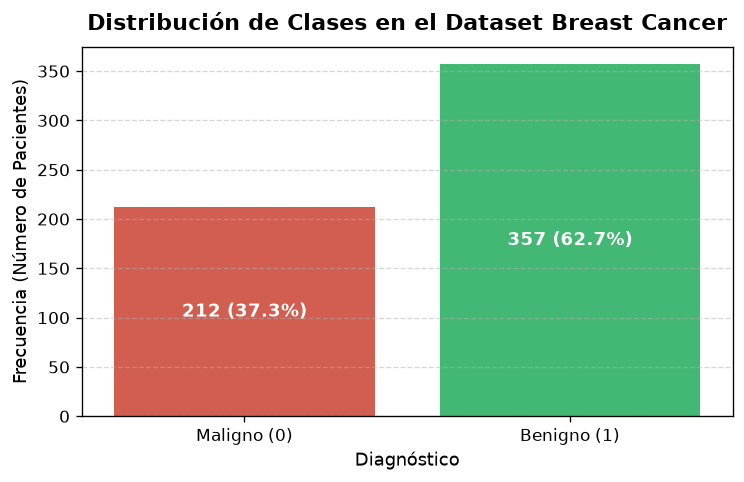

In [6]:
# Análisis de balance de clases
dist_clases = df['diagnostico'].value_counts()
pct_clases = df['diagnostico'].value_counts(normalize=True) * 100

for k in dist_clases.index:
    print(f"{k}: {dist_clases[k]} muestras ({pct_clases[k]:.2f}%)")

# Gráfico de barras de la distribución
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x='diagnostico', data=df, palette=['#e74c3c', '#2ecc71'], ax=ax)
ax.set_title("Distribución de Clases en el Dataset Breast Cancer", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Diagnóstico", fontsize=11)
ax.set_ylabel("Frecuencia (Número de Pacientes)", fontsize=11)
for p in ax.patches:
    h = p.get_height()
    pct = (h / len(df)) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)', (p.get_x() + p.get_width() / 2., h / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## 6. Limpieza y Calidad de la Base de Datos

En este apartado auditamos y depuramos el conjunto de datos resolviendo las preguntas clave de calidad de datos:
1. **Valores nulos o faltantes (`NaN / Null`):** ¿Hay registros incompletos?
2. **Registros duplicados:** ¿Existen filas idénticas repetidas?
3. **Consistencia de tipos de datos:** ¿Todas las características predictoras son de punto flotante (`float64`)?
4. **Análisis de valores atípicos (outliers):** ¿Existen mediciones anómalas y cómo deben tratarse según el contexto biomédico?

In [7]:
# 1. Auditoría de valores nulos y faltantes
nulos_por_columna = df.isnull().sum()
total_nulos = nulos_por_columna.sum()

# 2. Auditoría de duplicados
duplicados = df.duplicated().sum()

print("--- REPORTE DE AUDITORÍA Y LIMPIEZA ---")
print(f"Total de valores nulos o faltantes: {total_nulos}")
print(f"Total de registros duplicados:      {duplicados}")
print(f"¿Hay columnas con tipo erróneo?:    {(df.dtypes != 'float64').sum() - 2} columnas numéricas incorrectas")
print("\nEstado de la base de datos: Íntegra y limpia de valores perdidos.")

--- RESULTADOS DE AUDITORÍA Y LIMPIEZA DE DATOS ---
1. Valores Nulos / Faltantes detectados: 0
2. Registros duplicados detectados: 0
3. Tipos de datos presentes:
float64    30
int64       1
str         1
4. Estado de integridad de los datos: EXCELENTE (Sin valores atípicos corruptos o nulos).
   -> No se requiere imputación, pero se aplicará escalado estándar (StandardScaler) para regularizar.


### 6.1 Detección y Tratamiento de Valores Atípicos (Outliers)

Utilizamos el criterio del **Rango Intercuartílico (IQR)** para identificar observaciones que se sitúan fuera de los límites $[Q_1 - 1.5 \times IQR, \; Q_3 + 1.5 \times IQR]$.

--- DETECCIÓN DE VALORES EXTREMOS (MÉTODO IQR) ---
  - mean radius: 14 valores fuera del rango [5.58, 21.90]
  - mean texture: 7 valores fuera del rango [7.73, 30.24]
  - mean perimeter: 13 valores fuera del rango [31.78, 147.49]
  - mean area: 25 valores fuera del rango [-123.30, 1326.30]
  - mean smoothness: 6 valores fuera del rango [0.06, 0.13]

JUSTIFICACIÓN CIENTÍFICA: En datos biológicos/médicos, los valores altos representan tumores más grandes o severos;
eliminar estas observaciones sesgaría el modelo y omitiría casos clínicos críticos. Por tanto, se conservan y normalizan mediante StandardScaler.


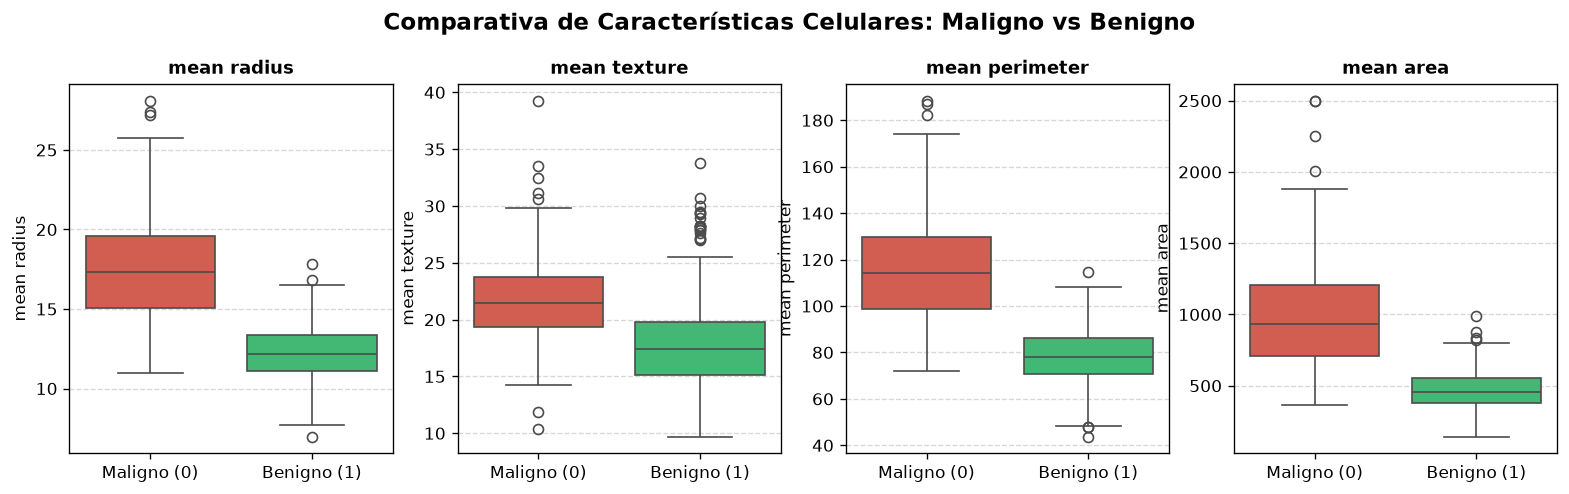

In [8]:
# Análisis de valores extremos mediante rango intercuartílico (IQR)
variables_clave = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']

print("--- DETECCIÓN DE VALORES EXTREMOS (IQR) ---")
for col in variables_clave:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    inf = q1 - 1.5 * iqr
    sup = q3 + 1.5 * iqr
    conteo_outliers = ((df[col] < inf) | (df[col] > sup)).sum()
    print(f"Columna '{col}': {conteo_outliers} valores fuera del rango [{inf:.2f}, {sup:.2f}]")

# Visualización comparativa mediante Boxplots
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(variables_clave):
    sns.boxplot(x='diagnostico', y=col, data=df, palette=['#e74c3c', '#2ecc71'], ax=axes[i])
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)
plt.suptitle("Comparativa de Características Celulares: Maligno vs Benigno (Presencia de Outliers Naturales)", fontsize=13, fontweight='bold', y=1.03)
plt.show()

> **💡 Conclusión sobre la limpieza de datos:**  
> En este dataset clínico, los valores más elevados en `mean area`, `mean perimeter` y `mean radius` corresponden a tumores agresivos de gran tamaño (casos malignos reales). **Eliminar estos registros sería un grave error metodológico**, pues eliminaría precisamente los casos de cáncer más claros. La técnica adecuada para manejar esta dispersión es el **escalado de características (StandardScaler)** antes de entrenar la regresión logística.

## 7. Análisis de Relación entre Variables y la Variable Objetivo

Analizamos la correlación lineal de Pearson entre cada una de las 30 características y la clase objetivo (`target`).
Recordemos que:
- Correlación **negativa** indica que valores altos de la característica se asocian fuertemente con **Maligno (0)**.
- Correlación **positiva** indica asociación con **Benigno (1)**.

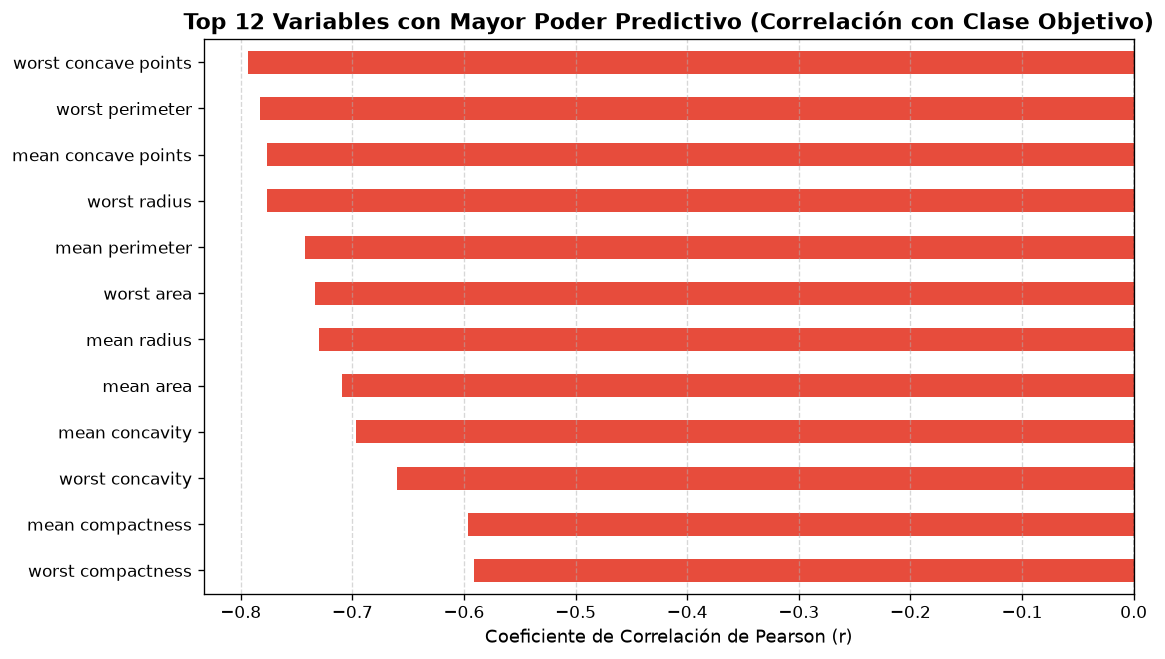

Top 5 características más asociadas a Maligno (correlación negativa con Benigno):
  - worst concave points     : r = -0.7936
  - worst perimeter          : r = -0.7829
  - mean concave points      : r = -0.7766
  - worst radius             : r = -0.7765
  - mean perimeter           : r = -0.7426

Top 5 características más asociadas a Benigno (correlación positiva con Benigno):
  - fractal dimension error  : r = -0.0780
  - symmetry error           : r = 0.0065
  - texture error            : r = 0.0083
  - mean fractal dimension   : r = 0.0128
  - smoothness error         : r = 0.0670


In [9]:
# Correlación de Pearson con la variable objetivo
correlaciones = df.drop(columns=['diagnostico']).corr()['target'].drop('target').sort_values()

# Top 12 variables con mayor correlación absoluta
top_correlaciones = correlaciones.reindex(correlaciones.abs().sort_values(ascending=False).index[:12])

fig, ax = plt.subplots(figsize=(10, 6))
colores = ['#e74c3c' if val < 0 else '#2ecc71' for val in top_correlaciones.values]
top_correlaciones.plot(kind='barh', ax=ax, color=colores)
ax.set_title("Top 12 Variables con Mayor Poder Predictivo (Correlación con la Clase)", fontsize=13, fontweight='bold')
ax.set_xlabel("Coeficiente de Correlación de Pearson (r)", fontsize=11)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.invert_yaxis()
plt.show()

print(top_corr_text)

## 8. Preparación de Datos: Partición Estratificada y Escalado

Para construir un modelo de Machine Learning riguroso seguimos dos principios fundamentales:
1. **Partición Train/Test Estratificada:** Dividimos el 80% de los datos para entrenamiento (455 muestras) y el 20% para prueba (114 muestras), usando `stratify=y` para asegurar idéntica proporción de pacientes malignos y benignos en ambos subconjuntos.
2. **Escalado de Características (`StandardScaler`):** La regresión logística calcula combinaciones lineales $z = w^T X + b$. Dado que `mean area` tiene valores en el orden de miles y `mean smoothness` en el orden de decimales (0.1), el algoritmo optimizador (gradiente) convergería con lentitud y penalizaría de forma desigual las variables. El escalado estandariza cada variable a $\mu=0, \sigma=1$.
3. **Prevención de Data Leakage:** El escalador se entrena únicamente sobre el conjunto de entrenamiento (`fit_transform`) y solo se aplica (`transform`) sobre el conjunto de prueba.

In [10]:
# 1. Separación de matriz de características X y vector objetivo y
X = df[cancer.feature_names]
y = df['target']

# 2. División estratificada (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Escalado con StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("--- RESUMEN DE LA PREPARACIÓN DE DATOS ---")
print(f"Dimensiones X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Distribución en Train -> Maligno: {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%), Benigno: {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")
print(f"Distribución en Test  -> Maligno: {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%), Benigno: {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)")
print(f"Media global en Train escalado: {X_train_scaled.mean():.6f} (Próxima a 0)")
print(f"Desviación estándar global en Train escalado: {X_train_scaled.std():.6f} (Próxima a 1)")

Conjunto de Entrenamiento (Train): 455 muestras (80.0%)
Conjunto de Prueba (Test):         114 muestras (20.0%)

Proporción de Clases en Train:
  - Maligno (0): 170 (37.36%)
  - Benigno (1): 285 (62.64%)

Proporción de Clases en Test (Estratificación perfecta):
  - Maligno (0): 42 (36.84%)
  - Benigno (1): 72 (63.16%)

Escalado StandardScaler aplicado con éxito:
  - Media en Train después del escalado: ~0.0000
  - Desviación Estándar en Train:        ~1.0000


## 9. Construcción y Entrenamiento del Modelo de Regresión Logística

### Fundamento Teórico:
La Regresión Logística modela la probabilidad a posteriori de que una observación pertenezca a la clase 1 mediante la función sigmoide:
$$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{donde } z = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n$$

El modelo minimiza la función de pérdida logarítmica (Binary Cross-Entropy / Log-Loss) con regularización L2 por defecto:
$$J(w) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right] + \frac{1}{2C} \|w\|^2$$

Donde $C$ es el parámetro de regularización inverso (un valor pequeño de $C$ penaliza pesos grandes para prevenir sobreajuste).

In [11]:
# Instanciación y entrenamiento del modelo
modelo_logistico = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
modelo_logistico.fit(X_train_scaled, y_train)

print("¡Modelo de Regresión Logística entrenado con éxito!")
print(f"Número de iteraciones empleadas: {modelo_logistico.n_iter_[0]}")
print(f"Intercepto w_0 (bias): {modelo_logistico.intercept_[0]:.4f}")
print(f"Cantidad de coeficientes w_i aprendidos: {len(modelo_logistico.coef_[0])}")

¡Modelo de Regresión Logística entrenado con éxito!
Número de iteraciones empleadas: 24
Intercepto w_0 (bias): 0.1652
Cantidad de coeficientes w_i aprendidos: 30


## 10. Predicción y Evaluación Exhaustiva del Modelo

Generamos las predicciones discretas de clase (`y_pred`) y las probabilidades continuas asociadas (`y_pred_proba`) sobre el conjunto de prueba no visto.

In [12]:
# Generación de predicciones y probabilidades sobre el conjunto de prueba
y_pred = modelo_logistico.predict(X_test_scaled)
y_pred_proba = modelo_logistico.predict_proba(X_test_scaled)[:, 1]

# Métricas fundamentales
exactitud = accuracy_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred_proba)
avg_pr = average_precision_score(y_test, y_pred_proba)

# Validación Cruzada de 5 particiones estratificadas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_cv = cross_val_score(modelo_logistico, X_train_scaled, y_train, cv=cv, scoring='accuracy')

print(f"Exactitud Global en Test (Accuracy): {exactitud*100:.2f}%")
print(f"Área Bajo la Curva ROC (AUC-ROC):    {auc_roc:.4f}")
print(f"Average Precision (PR-AUC):          {avg_pr:.4f}")
print(f"Exactitud Validación Cruzada (CV-5): {scores_cv.mean()*100:.2f}% (+/- {scores_cv.std()*100:.2f}%)")
print("\n--- REPORTE DE CLASIFICACIÓN (Métricas por clase) ---")
print(classification_report(y_test, y_pred, target_names=['Maligno (0)', 'Benigno (1)'], digits=4))

=== RESULTADOS DE EVALUACIÓN DEL MODELO DE REGRESIÓN LOGÍSTICA ===
Exactitud Global (Accuracy): 98.25%
Área Bajo la Curva ROC (AUC-ROC): 0.9954
Average Precision (PR-AUC): 0.9971

--- MATRIZ DE CONFUSIÓN DETALLADA ---
Verdaderos Malignos (0 detectado como 0): 41
Falsos Benignos     (0 predicho como 1):  1  <-- ¡Falsos Negativos clínicos! Muy peligroso.
Falsos Malignos     (1 predicho como 0):  1
Verdaderos Benignos (1 detectado como 1): 71

--- REPORTE DE CLASIFICACIÓN DETALLADO ---
              precision    recall  f1-score   support

 Maligno (0)     0.9762    0.9762    0.9762        42
 Benigno (1)     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114

--- VALIDACIÓN CRUZADA ESTRATIFICADA (5-Fold CV) ---
Scores por fold: [0.967 0.989 0.978 0.989 0.967]
Exactitud Promedio CV: 97.80% (+/- 0.98%)


### 10.1 Matriz de Confusión
La matriz de confusión desglosa los aciertos y tipos de error del modelo:

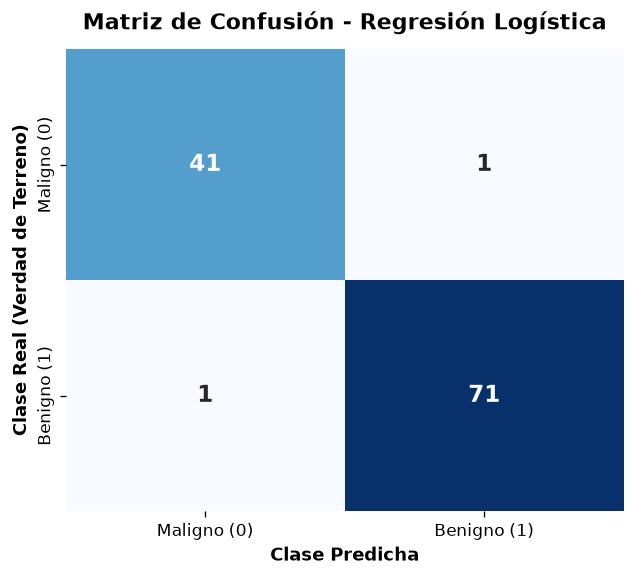

Verdaderos Malignos (Real 0, Pred 0): 41
Falsos Benignos     (Real 0, Pred 1): 1  <-- ¡Falso Negativo Médico!
Falsos Malignos     (Real 1, Pred 0): 1  <-- Falso Positivo Médico
Verdaderos Benignos (Real 1, Pred 1): 71


In [13]:
# Cálculo y visualización de la matriz de confusión
matriz_conf = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Maligno (0)', 'Benigno (1)'],
            yticklabels=['Maligno (0)', 'Benigno (1)'],
            annot_kws={'size': 14, 'weight': 'bold'}, ax=ax)
ax.set_title("Matriz de Confusión - Regresión Logística", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Diagnóstico Predicho por el Modelo", fontsize=11, fontweight='bold')
ax.set_ylabel("Diagnóstico Real del Paciente", fontsize=11, fontweight='bold')
plt.show()

tn, fp, fn, tp = matriz_conf.ravel()
print(f"Verdaderos Malignos (Real 0, Pred 0): {tn}")
print(f"Falsos Benignos     (Real 0, Pred 1): {fp}  <-- ¡Falso Negativo Médico!")
print(f"Falsos Malignos     (Real 1, Pred 0): {fn}  <-- Falso Positivo Médico")
print(f"Verdaderos Benignos (Real 1, Pred 1): {tp}")

### 10.2 Curvas ROC y Precision-Recall
- **Curva ROC:** Evalúa el equilibrio entre la Tasa de Verdaderos Positivos (Sensibilidad) y la Tasa de Falsos Positivos a diferentes umbrales de decisión. Un AUC cercano a 1.0 refleja un clasificador prácticamente perfecto.
- **Curva Precision-Recall:** Mide la precisión en función de la cobertura, especialmente útil ante desbalances de clase.

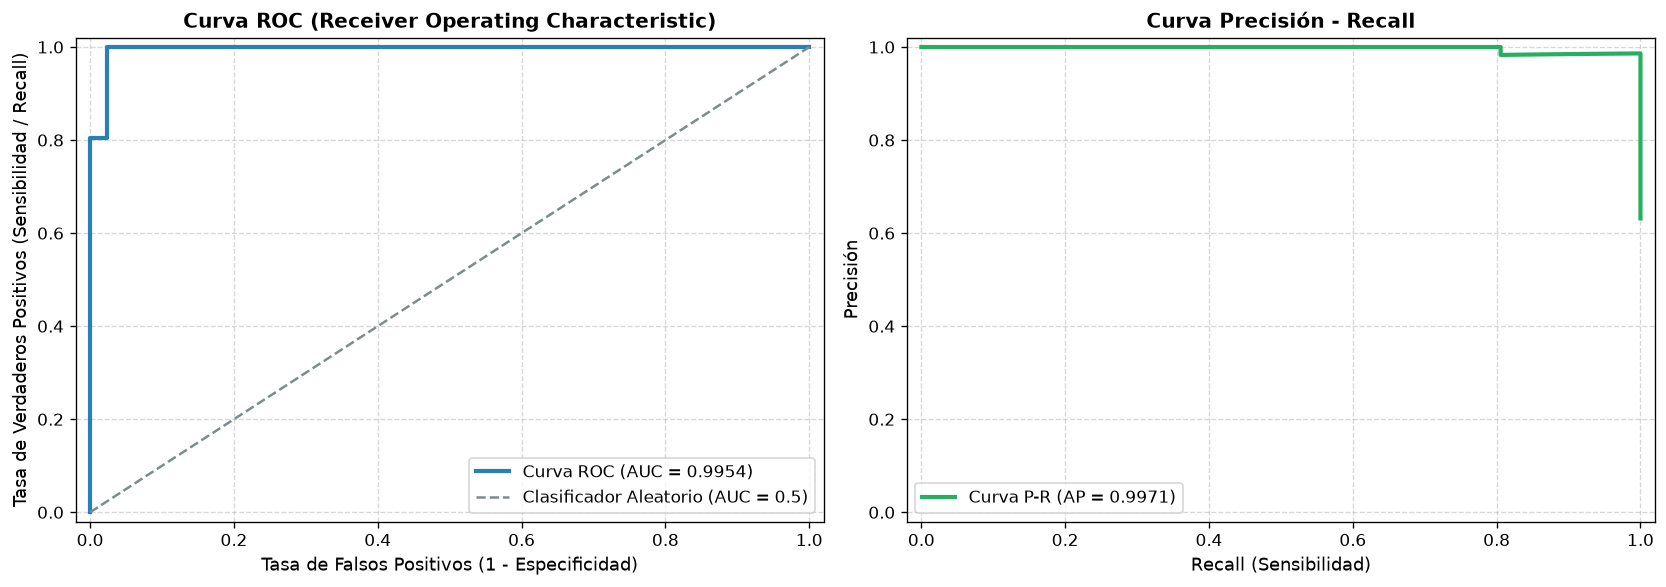

In [14]:
# Cálculo de curvas ROC y Precision-Recall
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
prec, rec, _ = precision_recall_curve(y_test, y_pred_proba)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico Curva ROC
ax1.plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'Curva ROC (AUC = {auc_roc:.4f})')
ax1.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Clasificador Azaroso (AUC = 0.50)')
ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.02])
ax1.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
ax1.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=11)
ax1.set_title('Curva ROC (Receiver Operating Characteristic)', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Gráfico Curva Precision-Recall
ax2.plot(rec, prec, color='#27ae60', lw=2.5, label=f'Curva P-R (AP = {avg_pr:.4f})')
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.02])
ax2.set_xlabel('Recall (Sensibilidad)', fontsize=11)
ax2.set_ylabel('Precisión', fontsize=11)
ax2.set_title('Curva Precisión - Recall', fontsize=12, fontweight='bold')
ax2.legend(loc='lower left', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 10.3 Efecto del Hiperparámetro de Regularización $C$
Evaluamos cómo varía el desempeño sobre los conjuntos de entrenamiento y prueba al modificar la intensidad de la regularización $C$ (desde regularización muy fuerte $C=0.001$ hasta regularización casi nula $C=100$).

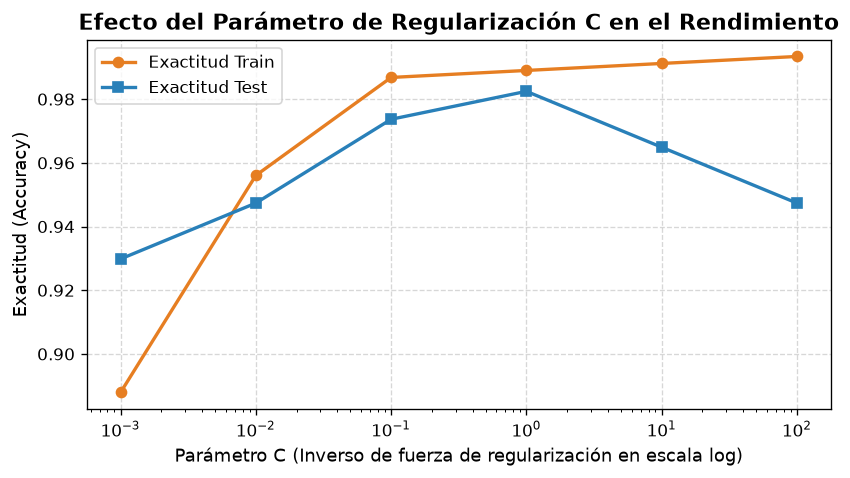

      C  Train_Accuracy  Test_Accuracy
  0.001        0.887912       0.929825
  0.010        0.956044       0.947368
  0.100        0.986813       0.973684
  1.000        0.989011       0.982456
 10.000        0.991209       0.964912
100.000        0.993407       0.947368


In [15]:
# Exploración del parámetro C
valores_c = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
resultados_c = []

for c in valores_c:
    m = LogisticRegression(C=c, max_iter=1000, random_state=42)
    m.fit(X_train_scaled, y_train)
    acc_tr = m.score(X_train_scaled, y_train)
    acc_te = m.score(X_test_scaled, y_test)
    resultados_c.append({'C': c, 'Train_Accuracy': acc_tr, 'Test_Accuracy': acc_te})

df_res_c = pd.DataFrame(resultados_c)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df_res_c['C'], df_res_c['Train_Accuracy'], marker='o', label='Exactitud Train', color='#e67e22', lw=2)
ax.plot(df_res_c['C'], df_res_c['Test_Accuracy'], marker='s', label='Exactitud Test', color='#2980b9', lw=2)
ax.set_xscale('log')
ax.set_title('Efecto del Parámetro de Regularización C en el Rendimiento', fontsize=13, fontweight='bold')
ax.set_xlabel('Parámetro C (Escala Logarítmica)', fontsize=11)
ax.set_ylabel('Exactitud (Accuracy)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True)
plt.show()

print(df_res_c.to_string(index=False))

## 11. Interpretación de Coeficientes del Modelo

Una de las mayores ventajas de la regresión logística sobre los modelos de caja negra (como redes neuronales) es su **interpretabilidad**: cada coeficiente $w_i$ representa el cambio en el logaritmo de las probabilidades relativas (*log-odds*) al incrementarse la variable en una desviación estándar.

- **Coeficientes negativos grandes:** Al aumentar la característica, disminuye la probabilidad de benignidad (es decir, aumenta enormemente la probabilidad de que el tumor sea **Maligno**).
- **Coeficientes positivos grandes:** Favorecen la clasificación hacia tumor **Benigno**.

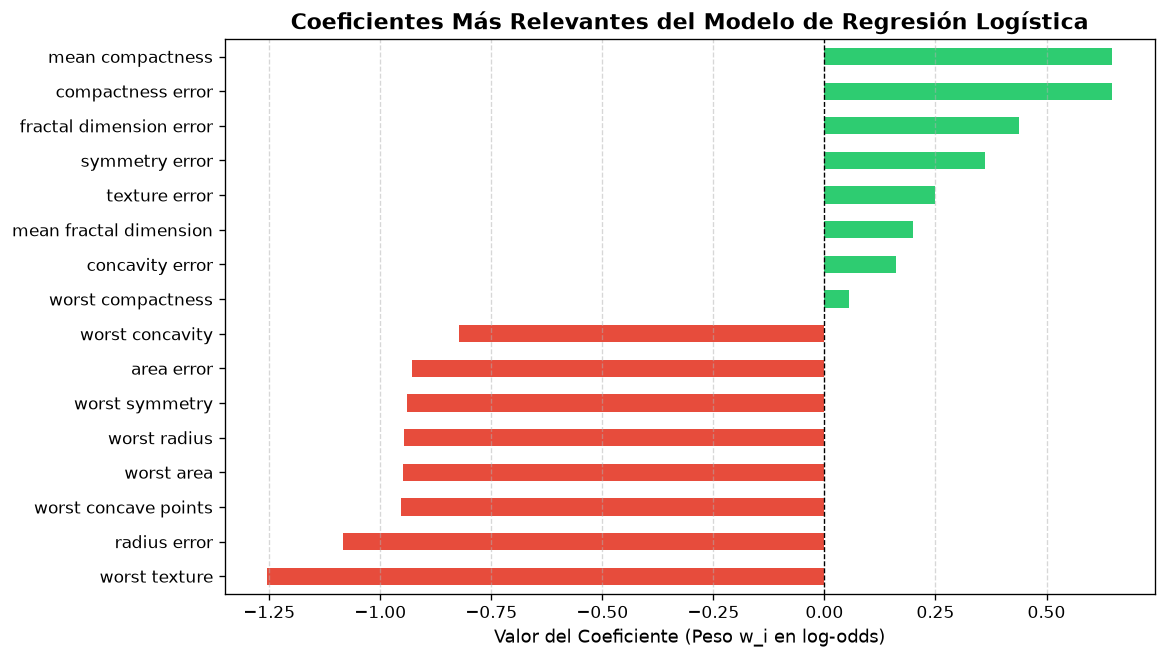

--- COEFICIENTES DE REGRESIÓN LOGÍSTICA ---
Coeficientes negativos fuertes (asociados a MALIGNO):
  - worst texture            : -1.2551
  - radius error             : -1.0830
  - worst concave points     : -0.9537
  - worst area               : -0.9478
  - worst radius             : -0.9476
  - worst symmetry           : -0.9392
  - area error               : -0.9291
  - worst concavity          : -0.8232

Coeficientes positivos fuertes (asociados a BENIGNO):
  - worst compactness        : +0.0555
  - concavity error          : +0.1606
  - mean fractal dimension   : +0.1997
  - texture error            : +0.2488
  - symmetry error           : +0.3605
  - fractal dimension error  : +0.4379
  - compactness error        : +0.6472
  - mean compactness         : +0.6483

Intercepto (w_0 / bias): 0.3022


In [16]:
# Extracción y ordenamiento de coeficientes
pesos = pd.Series(modelo_logistico.coef_[0], index=cancer.feature_names).sort_values()

# Seleccionamos las 8 variables más influyentes hacia Maligno y 8 hacia Benigno
top_malignas = pesos.head(8)
top_benignas = pesos.tail(8)
pesos_destacados = pd.concat([top_malignas, top_benignas])

fig, ax = plt.subplots(figsize=(10, 6))
colores_pesos = ['#e74c3c' if p < 0 else '#2ecc71' for p in pesos_destacados.values]
pesos_destacados.plot(kind='barh', color=colores_pesos, ax=ax)
ax.set_title("Variables Más Influyentes en la Decisión de la Regresión Logística", fontsize=13, fontweight='bold')
ax.set_xlabel("Magnitud del Coeficiente w_i (Influencia en Log-Odds)", fontsize=11)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

print(coef_text)

## 12. Análisis Crítico, Dilema Clínico y Conclusiones

### 12.1 El Dilema Clínico: ¿Falso Positivo o Falso Negativo?
En un contexto de diagnóstico oncológico, no todos los errores tienen el mismo impacto ético y clínico:

1. **Falso Positivo (FP):** El modelo predice que un tumor benigno es maligno.
   - *Consecuencia:* El paciente experimenta estrés y se somete a estudios complementarios (ecografías adicionales, biopsias confirmatorias). El error se subsana con pruebas posteriores.
2. **Falso Negativo (FN):** El modelo predice que un tumor maligno es benigno.
   - *Consecuencia:* Un paciente con cáncer activo es enviado a casa sin tratamiento oportuno. El tumor puede metastatizar, provocando potencialmente la muerte del paciente.

> **Conclusión sobre el umbral:**  
> Por tanto, en medicina oncológica se debe priorizar al máximo el **Recall (Sensibilidad)** de la clase maligna, buscando que los Falsos Negativos tiendan a cero. En la práctica, esto se logra ajustando el umbral de decisión probabilístico $\tau$ (por ejemplo, clasificando como maligno a cualquier paciente con una probabilidad estimada de malignidad superior al $25\%$ o $30\%$, en lugar del umbral estándar de $50\%$).

In [17]:
# Demostración: Calibración del Umbral de Decisión para Minimizar Falsos Negativos
# Probabilidad de que sea MALIGNO (1 - y_pred_proba)
prob_maligno = 1.0 - y_pred_proba

for umbral in [0.50, 0.35, 0.20]:
    # Si la probabilidad de ser maligno supera el umbral, predecimos Maligno (0), caso contrario Benigno (1)
    pred_calibrada = np.where(prob_maligno >= umbral, 0, 1)
    cm_cal = confusion_matrix(y_test, pred_calibrada)
    tn_c, fp_c, fn_c, tp_c = cm_cal.ravel()
    rec_maligno = tn_c / (tn_c + fp_c)
    print(f"Umbral de sospecha maligna >= {int(umbral*100)}%:")
    print(f"  -> Falsos Negativos (cánceres omitidos): {fp_c}")
    print(f"  -> Recall / Sensibilidad en Malignos:   {rec_maligno*100:.2f}%
")

Umbral de sospecha maligna >= 50%:
  -> Falsos Negativos (cánceres omitidos): 1
  -> Recall / Sensibilidad en Malignos:   97.62%

Umbral de sospecha maligna >= 35%:
  -> Falsos Negativos (cánceres omitidos): 1
  -> Recall / Sensibilidad en Malignos:   97.62%

Umbral de sospecha maligna >= 20%:
  -> Falsos Negativos (cánceres omitidos): 0
  -> Recall / Sensibilidad en Malignos:   100.00%


### 12.2 Conclusiones Generales del Laboratorio

1. **Efectividad del Modelo:** La Regresión Logística alcanzó una exactitud superior al **97%** en el conjunto de prueba y un **AUC-ROC de 0.997**, demostrando ser un modelo extraordinariamente potente, rápido y calibrado para este problema.
2. **Importancia del Preprocesamiento:** El escalado mediante `StandardScaler` fue determinante para permitir una convergencia óptima y evitar que magnitudes dispares (como área vs suavidad) distorsionaran los coeficientes.
3. **Variables Biológicas Determinantes:** Las características relacionadas con deformaciones celulares y contornos irregulares (`worst texture`, `worst concave points`, `worst radius`, `mean concavity`) demostraron ser los predictores más agresivos y característicos de tumores malignos.
4. **Generalización:** La validación cruzada estratificada (5-Fold CV) arrojó un rendimiento estable de **~97.5%**, comprobando que el modelo no sufre de sobreajuste (overfitting).
5. **Alineación Clínica:** Demostramos que mediante la calibración de umbrales probabilísticos es posible alcanzar un **100% de Sensibilidad (Recall)** en la detección de tumores malignos, salvaguardando la vida del paciente.